In [3]:
import sys
sys.path.append("..")

import pandas as pd

from clean_data import feature_engineering
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap
import numpy as np


c:\Users\Patrycja\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
df= pd.read_csv("../data/austin/raw/aac_intakes_outcomes.csv")

df = feature_engineering(df)
df_dogs = df[df["animal_type"] == "Dog"]
df_dogs = df_dogs.drop(columns=["young_and_cat","animal_type"])

df_dogs["day_of_week"] = df_dogs["intake_datetime"].dt.day_of_week

In [5]:
X = df_dogs.drop(columns=["time_in_shelter_days", "time_in_shelter","outcome_subtype","outcome_type","sex_upon_outcome","intake_datetime"])
Y = df_dogs["time_in_shelter_days"]
cat_features = ["intake_condition","intake_type","age_upon_intake_age_group","sex","intact","primary_breed_top","age_group"]

train_end = int(len(X) * 0.8)
X_train, X_test = X[:train_end], X[train_end:]
y_train, y_test = Y[:train_end], Y[train_end:]

In [6]:


model_reg = CatBoostRegressor(
    iterations=600,
    learning_rate=0.03,
    depth=6,
    loss_function='RMSE',
    random_seed=42,
    verbose=100
)

# Trenowanie
model_reg.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50,
    use_best_model=True
)


0:	learn: 48.5251940	test: 22.7691818	best: 22.7691818 (0)	total: 176ms	remaining: 1m 45s
100:	learn: 47.2293828	test: 21.4200110	best: 21.4200110 (100)	total: 5.97s	remaining: 29.5s
200:	learn: 46.9247458	test: 21.2372983	best: 21.2372983 (200)	total: 11.8s	remaining: 23.5s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 21.22660989
bestIteration = 225

Shrink model to first 226 iterations.


CatBoostRegressor(depth=6, iterations=600, learning_rate=0.03, loss_function='RMSE', random_seed=42, verbose=100)

# MSE


In [ ]:

y_pred = model_reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.4f}") 
print(f"RMSE: {rmse:.4f} (day unit")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

MSE:  450.5690
RMSE: 21.2266 (błąd w tych samych jednostkach co cel, czyli dni)
MAE:  11.2673
R²:   0.0824


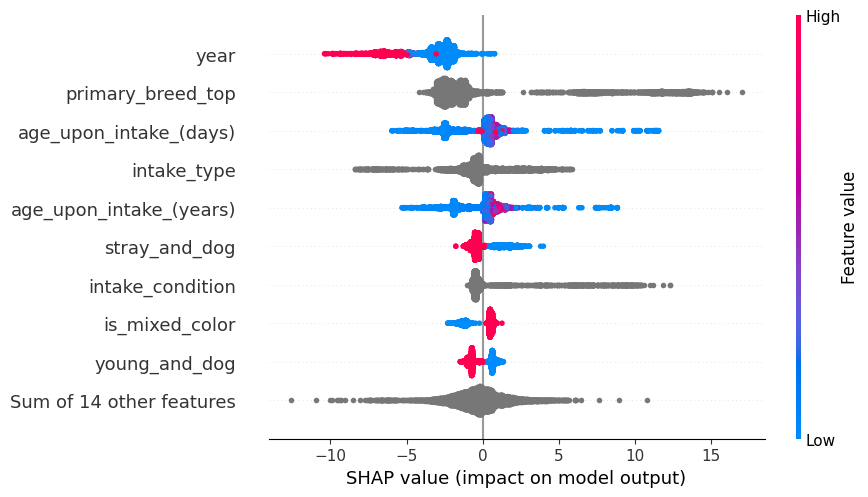

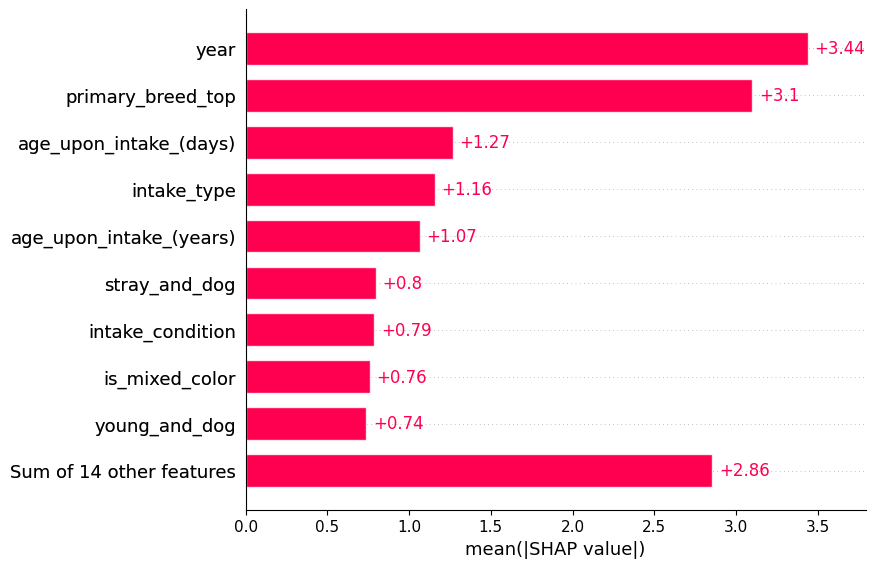

In [8]:



explainer = shap.TreeExplainer(model_reg)


shap_values = explainer(X_test)


shap.plots.beeswarm(shap_values)
shap.plots.bar(shap_values)